# LAB 2 – Khai phá dữ liệu: Bài 4 (Trang 26)
## Phân lớp chất lượng rượu vang đỏ Red Wine Quality (ID3, CART, Naïve Bayes)

**Sinh viên:** Nguyễn Khánh Hà – 6451071022


In [ ]:
DATA_PATH = "winequality-red.csv"   # dữ liệu Red Wine Quality
import pandas as pd, numpy as np
import matplotlib.pyplot as plt
from sklearn import tree, metrics
from sklearn.model_selection import train_test_split
from sklearn.naive_bayes import GaussianNB
print("Nguyễn Khánh Hà - 6451071022")

Nguyễn Khánh Hà - 6451071022


## Chuẩn bị dữ liệu

In [ ]:
print("Nguyễn Khánh Hà - 6451071022")
df = pd.read_csv(DATA_PATH, sep=None, engine="python")   # tự nhận dấu phân cách (, hoặc ;)
print("Kích thước dữ liệu ban đầu:", df.shape)
print("Số giá trị trống mỗi cột:\n", df.isna().sum())

df = df.dropna()    # xóa dòng chứa dữ liệu trống (nếu có)
print("\nKích thước dữ liệu sau khi xóa dòng trống:", df.shape)
print("\nPhân bố thuộc tính quyết định 'quality':\n", df["quality"].value_counts().sort_index())
df.head()

Nguyễn Khánh Hà - 6451071022
Kích thước dữ liệu ban đầu: (1599, 12)
Số giá trị trống mỗi cột:
 fixed acidity           0
volatile acidity        0
citric acid             0
residual sugar          0
chlorides               0
free sulfur dioxide     0
total sulfur dioxide    0
density                 0
pH                      0
sulphates               0
alcohol                 0
quality                 0
dtype: int64

Kích thước dữ liệu sau khi xóa dòng trống: (1599, 12)

Phân bố thuộc tính quyết định 'quality':
 quality
3     10
4     53
5    681
6    638
7    199
8     18
Name: count, dtype: int64


,fixed acidity,volatile acidity,citric acid,residual sugar,chlorides,free sulfur dioxide,total sulfur dioxide,density,pH,sulphates,alcohol,quality
0,7.4,0.70,0.00,1.9,0.076,11.0,34.0,0.9978,3.51,0.56,9.4,5
1,7.8,0.88,0.00,2.6,0.098,25.0,67.0,0.9968,3.20,0.68,9.8,5
2,7.8,0.76,0.04,2.3,0.092,15.0,54.0,0.9970,3.26,0.65,9.8,5
3,11.2,0.28,0.56,1.9,0.075,17.0,60.0,0.9980,3.16,0.58,9.8,6
4,7.4,0.70,0.00,1.9,0.076,11.0,34.0,0.9978,3.51,0.56,9.4,5


## Câu 3: Khảo sát độ tương đồng giữa các cột bằng hệ số Pearson
Cột nào có giá trị tương đồng cao (|r| > 0.8) thì loại bỏ (không xét thuộc tính quyết định `quality`).

Nguyễn Khánh Hà - 6451071022
                      fixed acidity  volatile acidity  citric acid  residual sugar  chlorides  free sulfur dioxide  total sulfur dioxide  density    pH  sulphates  alcohol  quality
fixed acidity                  1.00             -0.26         0.67            0.11       0.09                -0.15                 -0.11     0.67 -0.68       0.18    -0.06     0.12
volatile acidity              -0.26              1.00        -0.55            0.00       0.06                -0.01                  0.08     0.02  0.23      -0.26    -0.20    -0.39
citric acid                    0.67             -0.55         1.00            0.14       0.20                -0.06                  0.04     0.36 -0.54       0.31     0.11     0.23
residual sugar                 0.11              0.00         0.14            1.00       0.06                 0.19                  0.20     0.36 -0.09       0.01     0.04     0.01
chlorides                      0.09              0.06         0.20

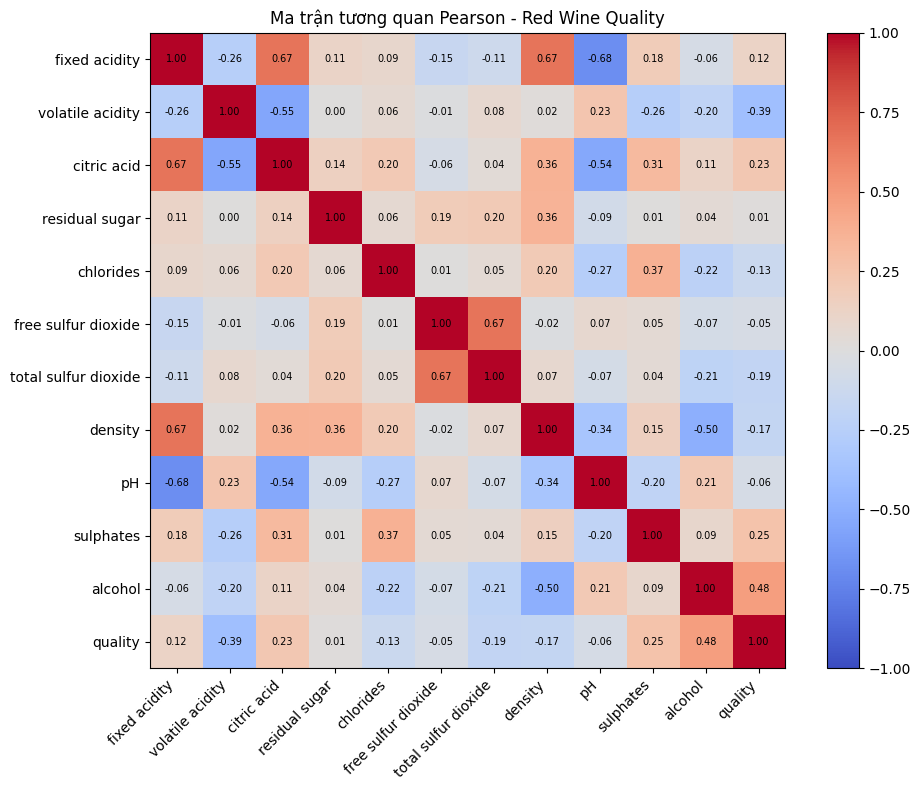


Các cột có |r| > 0.8 cần loại bỏ: không có
Cặp tương quan cao nhất giữa các thuộc tính: 0.68
Kích thước dữ liệu sau khi loại: (1599, 12)


In [ ]:
print("Nguyễn Khánh Hà - 6451071022")
THRESHOLD = 0.8
corr = df.corr(method="pearson")
print(corr.round(2).to_string())

plt.figure(figsize=(10, 8))
plt.imshow(corr, cmap="coolwarm", vmin=-1, vmax=1)
plt.colorbar()
plt.xticks(range(len(corr)), corr.columns, rotation=45, ha="right")
plt.yticks(range(len(corr)), corr.columns)
for i in range(len(corr)):
    for j in range(len(corr)):
        plt.text(j, i, f"{corr.iloc[i, j]:.2f}", ha="center", va="center", fontsize=7)
plt.title("Ma trận tương quan Pearson - Red Wine Quality")
plt.tight_layout()
plt.show()

feat_corr = corr.drop(index="quality", columns="quality").abs()
upper = feat_corr.where(np.triu(np.ones(feat_corr.shape), k=1).astype(bool))
to_drop = [c for c in upper.columns if (upper[c] > THRESHOLD).any()]
print(f"\nCác cột có |r| > {THRESHOLD} cần loại bỏ:", to_drop if to_drop else "không có")
print("Cặp tương quan cao nhất giữa các thuộc tính:", round(upper.max().max(), 2))
df = df.drop(columns=to_drop)
print("Kích thước dữ liệu sau khi loại:", df.shape)

## Câu 4: Tách dữ liệu thành thuộc tính bình thường và thuộc tính quyết định (`quality`)

In [ ]:
print("Nguyễn Khánh Hà - 6451071022")
X = df.drop(columns="quality")   # thuộc tính bình thường
y = df["quality"]                # thuộc tính quyết định
print("X:", X.shape, "| y:", y.shape)
X.head()

Nguyễn Khánh Hà - 6451071022
X: (1599, 11) | y: (1599,)


,fixed acidity,volatile acidity,citric acid,residual sugar,chlorides,free sulfur dioxide,total sulfur dioxide,density,pH,sulphates,alcohol
0,7.4,0.70,0.00,1.9,0.076,11.0,34.0,0.9978,3.51,0.56,9.4
1,7.8,0.88,0.00,2.6,0.098,25.0,67.0,0.9968,3.20,0.68,9.8
2,7.8,0.76,0.04,2.3,0.092,15.0,54.0,0.9970,3.26,0.65,9.8
3,11.2,0.28,0.56,1.9,0.075,17.0,60.0,0.9980,3.16,0.58,9.8
4,7.4,0.70,0.00,1.9,0.076,11.0,34.0,0.9978,3.51,0.56,9.4


## Câu 5: Chuyển các cột không phải dạng số về one-hot vector
Dữ liệu Red Wine chỉ gồm các cột số nên không có cột nào cần chuyển đổi.

In [ ]:
print("Nguyễn Khánh Hà - 6451071022")
cat_cols = X.select_dtypes(exclude="number").columns.tolist()
print("Các cột không phải dạng số:", cat_cols if cat_cols else "không có")
print("Kiểu dữ liệu các cột:\n", X.dtypes)

if cat_cols:                       # chỉ chuyển đổi khi có cột dạng chữ
    X = pd.get_dummies(X, columns=cat_cols, dtype=int)
print("\nSố cột của X:", X.shape[1])

Nguyễn Khánh Hà - 6451071022
Các cột không phải dạng số: không có
Kiểu dữ liệu các cột:
 fixed acidity           float64
volatile acidity        float64
citric acid             float64
residual sugar          float64
chlorides               float64
free sulfur dioxide     float64
total sulfur dioxide    float64
density                 float64
pH                      float64
sulphates               float64
alcohol                 float64
dtype: object

Số cột của X: 11


## Câu 6: Tách dữ liệu thành hai phần huấn luyện (70%) và kiểm thử (30%)

In [ ]:
print("Nguyễn Khánh Hà - 6451071022")
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.3, random_state=42)
print("X_train:", X_train.shape, "| y_train:", y_train.shape)
print("X_test :", X_test.shape,  "| y_test :", y_test.shape)

Nguyễn Khánh Hà - 6451071022
X_train: (1119, 11) | y_train: (1119,)
X_test : (480, 11) | y_test : (480,)


## Câu 7: Xây dựng cây ID3 (criterion = entropy), ma trận nhầm lẫn và biểu diễn cây

Nguyễn Khánh Hà - 6451071022
Classification report - ID3:

              precision    recall  f1-score   support

           3       0.00      0.00      0.00         1
           4       0.09      0.12      0.10        17
           5       0.71      0.67      0.69       195
           6       0.61      0.62      0.62       200
           7       0.46      0.46      0.46        61
           8       0.33      0.33      0.33         6

    accuracy                           0.60       480
   macro avg       0.37      0.37      0.37       480
weighted avg       0.61      0.60      0.60       480

Confusion matrix:
 [[  0   0   1   0   0   0]
 [  0   2   5   9   1   0]
 [  2  15 130  43   5   0]
 [  0   6  43 125  25   1]
 [  0   0   3  27  28   3]
 [  0   0   2   0   2   2]]


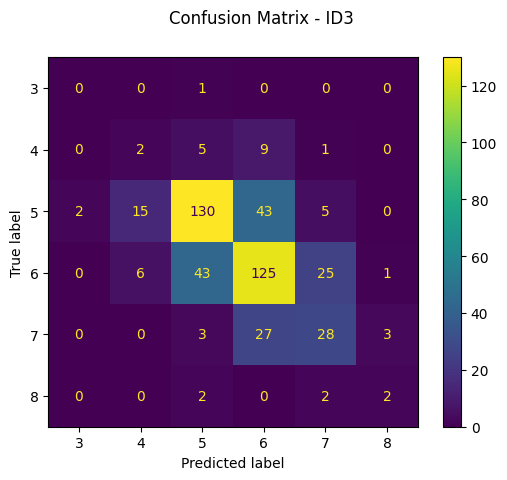

In [ ]:
print("Nguyễn Khánh Hà - 6451071022")
id3 = tree.DecisionTreeClassifier(criterion="entropy", random_state=42)
id3.fit(X_train, y_train)
pred_id3 = id3.predict(X_test)

print("Classification report - ID3:\n")
print(metrics.classification_report(y_test, pred_id3, zero_division=0))
disp = metrics.ConfusionMatrixDisplay.from_estimator(id3, X_test, y_test, values_format="d")
disp.figure_.suptitle("Confusion Matrix - ID3")
print("Confusion matrix:\n", disp.confusion_matrix)
plt.show()

Nguyễn Khánh Hà - 6451071022


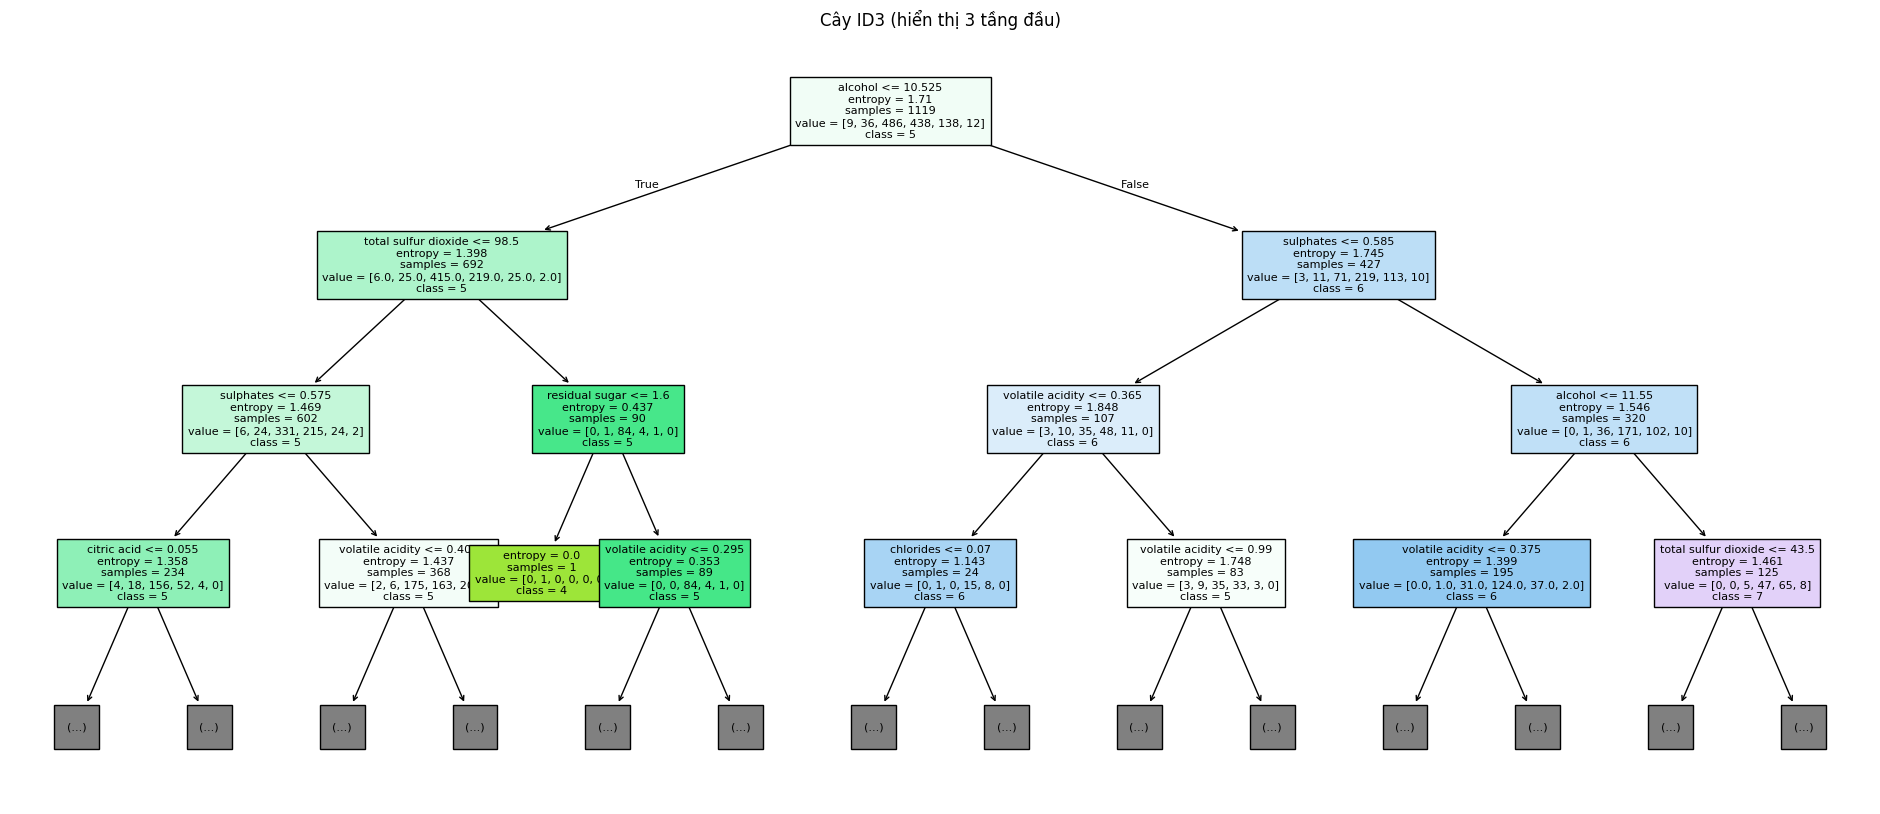

Độ sâu thực tế của cây: 18 | Số lá: 272


In [ ]:
print("Nguyễn Khánh Hà - 6451071022")
# Cây đầy đủ rất lớn nên chỉ vẽ 3 tầng đầu để dễ nhìn
plt.figure(figsize=(24, 10))
tree.plot_tree(id3, max_depth=3, feature_names=X.columns, class_names=[str(c) for c in id3.classes_],
               filled=True, fontsize=8)
plt.title("Cây ID3 (hiển thị 3 tầng đầu)")
plt.show()
print("Độ sâu thực tế của cây:", id3.get_depth(), "| Số lá:", id3.get_n_leaves())

## Câu 8: Lặp lại Câu 7 với cây CART (criterion = gini)

Nguyễn Khánh Hà - 6451071022
Classification report - CART:

              precision    recall  f1-score   support

           3       0.00      0.00      0.00         1
           4       0.07      0.06      0.06        17
           5       0.66      0.65      0.65       195
           6       0.57      0.60      0.59       200
           7       0.46      0.43      0.44        61
           8       0.33      0.17      0.22         6

    accuracy                           0.57       480
   macro avg       0.35      0.32      0.33       480
weighted avg       0.57      0.57      0.57       480

Confusion matrix:
 [[  0   0   1   0   0   0]
 [  0   1  10   5   1   0]
 [  1   8 126  58   2   0]
 [  0   5  48 121  26   0]
 [  0   1   6  26  26   2]
 [  0   0   0   3   2   1]]


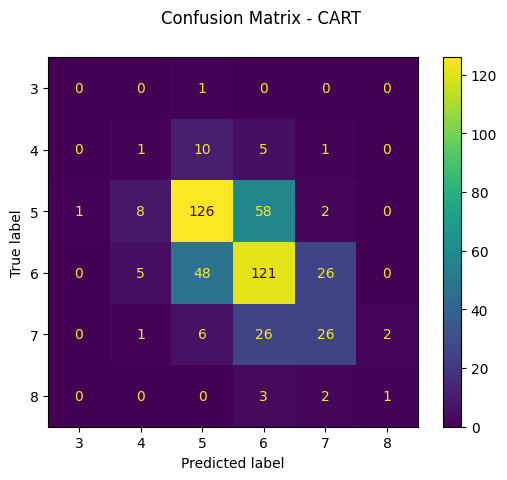

In [ ]:
print("Nguyễn Khánh Hà - 6451071022")
cart = tree.DecisionTreeClassifier(criterion="gini", random_state=42)
cart.fit(X_train, y_train)
pred_cart = cart.predict(X_test)

print("Classification report - CART:\n")
print(metrics.classification_report(y_test, pred_cart, zero_division=0))
disp = metrics.ConfusionMatrixDisplay.from_estimator(cart, X_test, y_test, values_format="d")
disp.figure_.suptitle("Confusion Matrix - CART")
print("Confusion matrix:\n", disp.confusion_matrix)
plt.show()

Nguyễn Khánh Hà - 6451071022


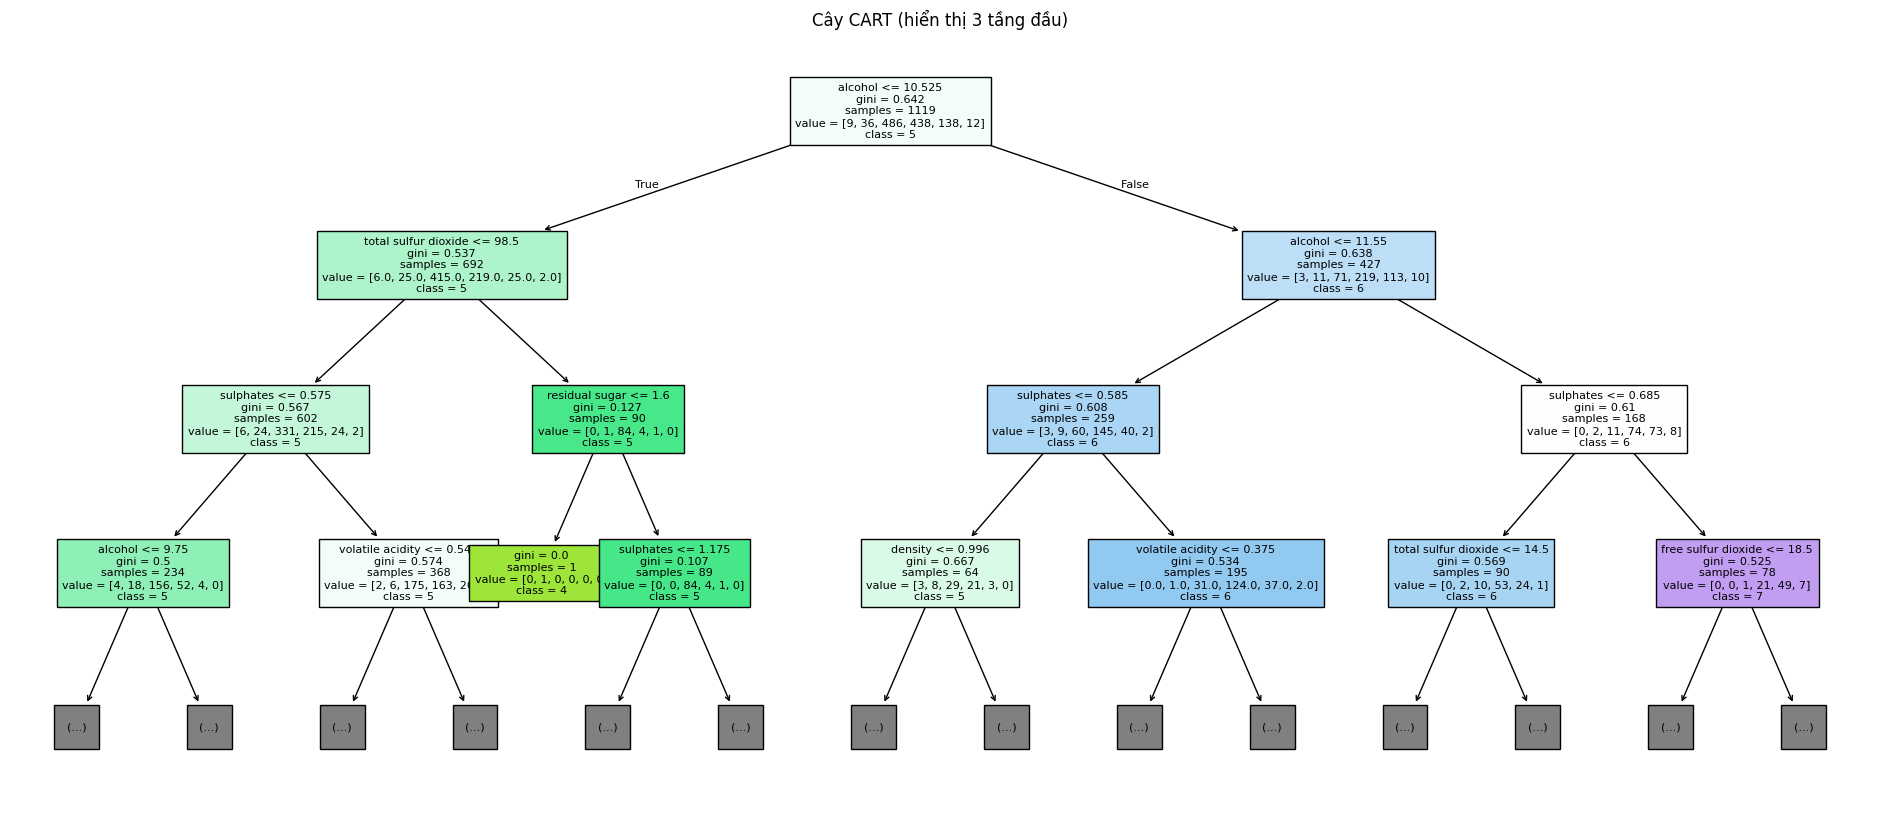

Độ sâu thực tế của cây: 19 | Số lá: 288


In [ ]:
print("Nguyễn Khánh Hà - 6451071022")
# Cây đầy đủ rất lớn nên chỉ vẽ 3 tầng đầu để dễ nhìn
plt.figure(figsize=(24, 10))
tree.plot_tree(cart, max_depth=3, feature_names=X.columns, class_names=[str(c) for c in cart.classes_],
               filled=True, fontsize=8)
plt.title("Cây CART (hiển thị 3 tầng đầu)")
plt.show()
print("Độ sâu thực tế của cây:", cart.get_depth(), "| Số lá:", cart.get_n_leaves())

## Câu 9: Xây dựng mô hình phân lớp bằng thuật toán Naïve Bayes và kiểm tra kết quả

Nguyễn Khánh Hà - 6451071022
Classification report - Naïve Bayes:

              precision    recall  f1-score   support

           3       0.00      0.00      0.00         1
           4       0.12      0.12      0.12        17
           5       0.68      0.62      0.65       195
           6       0.52      0.54      0.53       200
           7       0.40      0.49      0.44        61
           8       0.00      0.00      0.00         6

    accuracy                           0.54       480
   macro avg       0.29      0.29      0.29       480
weighted avg       0.55      0.54      0.54       480

Confusion matrix:
 [[  0   0   1   0   0   0]
 [  1   2   8   6   0   0]
 [  0   6 121  63   5   0]
 [  0   9  46 107  35   3]
 [  0   0   3  28  30   0]
 [  0   0   0   1   5   0]]


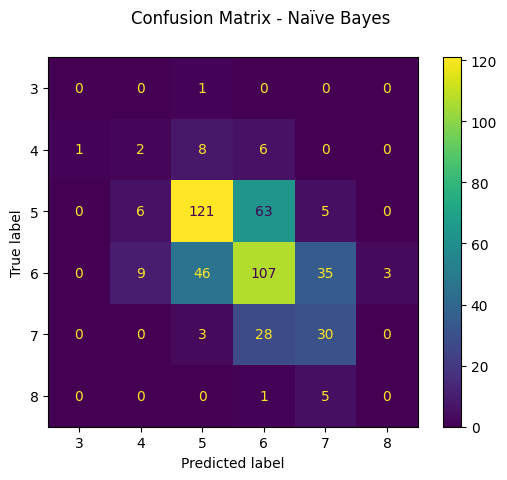

In [ ]:
print("Nguyễn Khánh Hà - 6451071022")
nb = GaussianNB()
nb.fit(X_train, y_train)
pred_nb = nb.predict(X_test)

print("Classification report - Naïve Bayes:\n")
print(metrics.classification_report(y_test, pred_nb, zero_division=0))
disp = metrics.ConfusionMatrixDisplay.from_estimator(nb, X_test, y_test, values_format="d")
disp.figure_.suptitle("Confusion Matrix - Naïve Bayes")
print("Confusion matrix:\n", disp.confusion_matrix)
plt.show()

## Câu 10: So sánh kết quả của các mô hình
`quality` có nhiều lớp (3–8) nên Precision, Recall, F-measure được tính theo trung bình có trọng số (weighted).

Nguyễn Khánh Hà - 6451071022
             Accuracy  Precision  Recall  F-measure
Mô hình                                            
ID3            0.5979     0.6079  0.5979     0.6026
CART           0.5729     0.5692  0.5729     0.5704
Naive Bayes    0.5417     0.5471  0.5417     0.5433


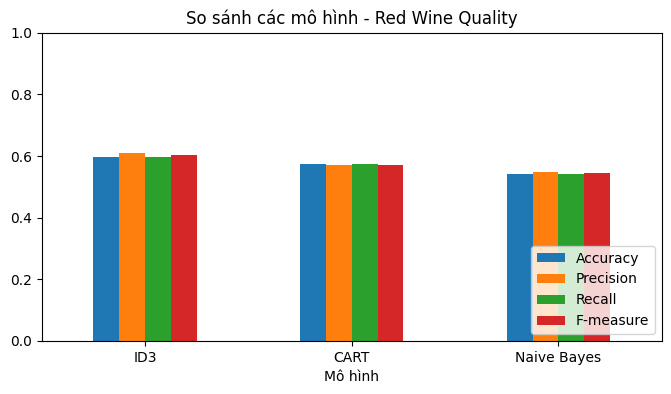


=> Mô hình có Accuracy cao nhất: ID3 (0.5979)


In [ ]:
print("Nguyễn Khánh Hà - 6451071022")
preds = {"ID3": pred_id3, "CART": pred_cart, "Naive Bayes": pred_nb}
rows = []
for name, p in preds.items():
    rows.append({
        "Mô hình": name,
        "Accuracy":  metrics.accuracy_score(y_test, p),
        "Precision": metrics.precision_score(y_test, p, average="weighted", zero_division=0),
        "Recall":    metrics.recall_score(y_test, p, average="weighted", zero_division=0),
        "F-measure": metrics.f1_score(y_test, p, average="weighted", zero_division=0),
    })
result = pd.DataFrame(rows).set_index("Mô hình").round(4)
print(result)

result.plot(kind="bar", figsize=(8, 4), rot=0)
plt.title("So sánh các mô hình - Red Wine Quality"); plt.ylim(0, 1); plt.legend(loc="lower right")
plt.show()

best = result["Accuracy"].idxmax()
print(f"\n=> Mô hình có Accuracy cao nhất: {best} ({result.loc[best, 'Accuracy']:.4f})")

**Nhận xét:** Dữ liệu có 6 lớp chất lượng (3–8) và rất mất cân bằng (lớp 5 và 6 chiếm phần lớn, lớp 3 chỉ có 10 mẫu) nên độ chính xác của cả ba mô hình đều thấp hơn nhiều so với Bài 2. ID3 đạt kết quả tốt nhất (Accuracy 0.5979, F-measure 0.6026), tiếp theo là CART (0.5729, 0.5704) và Naïve Bayes thấp nhất (0.5417, 0.5433). Các mô hình dự đoán khá tốt hai lớp phổ biến 5 và 6 nhưng gần như không nhận ra các lớp hiếm 3, 4, 8 (precision và recall rất thấp). Naïve Bayes không dự đoán đúng mẫu nào của lớp 8, có thể do giả định các thuộc tính độc lập và phân phối chuẩn không phù hợp với dữ liệu hóa lý của rượu.